<a href="https://colab.research.google.com/github/Narmadha-H/MLA0202-FML/blob/main/ML16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Setup complete


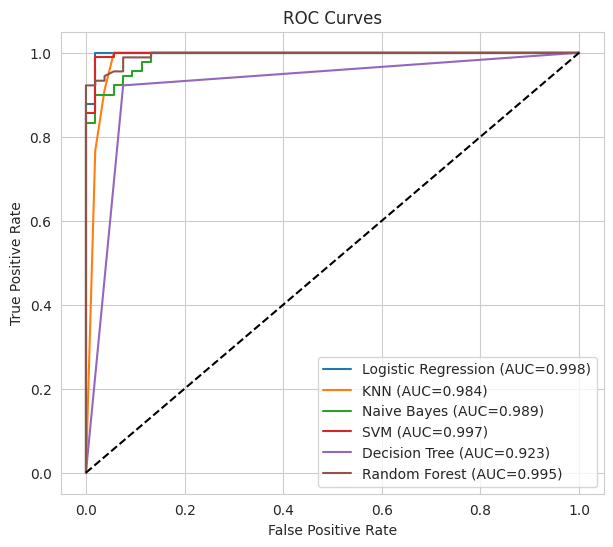

                     Accuracy  Precision  Recall     F1
Model                                                  
Logistic Regression     0.986      0.989   0.989  0.989
KNN                     0.979      0.968   1.000  0.984
Naive Bayes             0.937      0.926   0.978  0.951
SVM                     0.979      0.989   0.978  0.983
Decision Tree           0.923      0.954   0.922  0.938
Random Forest           0.958      0.957   0.978  0.967


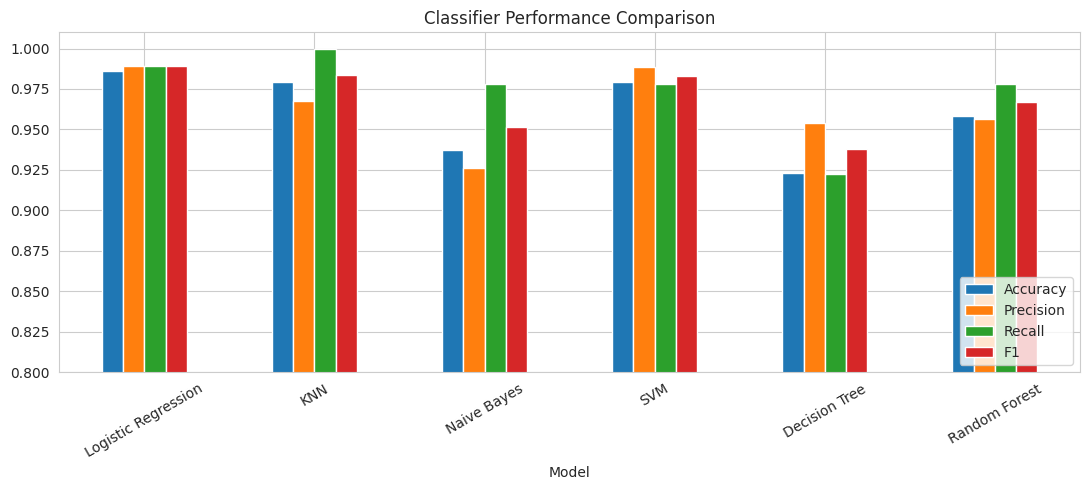

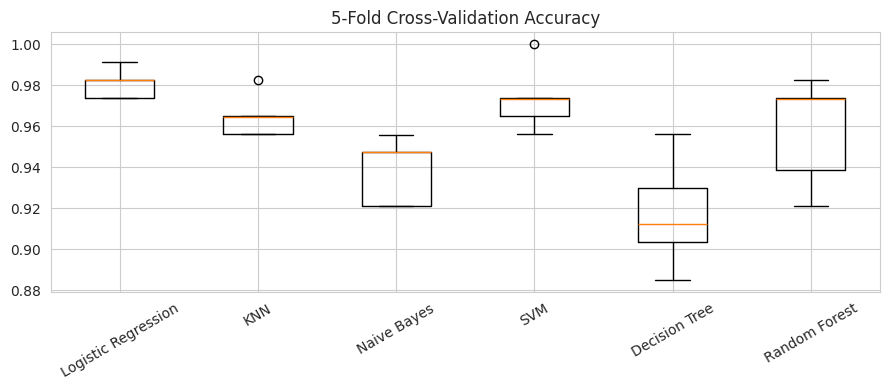

Best model by accuracy: Logistic Regression


In [1]:
# ---------- Common imports and helper functions ----------
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

from sklearn.datasets import load_iris, load_breast_cancer, fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression, Perceptron as SkPerceptron
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report, roc_curve, auc,
                             r2_score, mean_squared_error, mean_absolute_error,
                             precision_score, recall_score, f1_score)

sns.set_style("whitegrid")
rng = np.random.default_rng(42)

def plot_cm(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    plt.tight_layout(); plt.show()

def plot_reg(y_true, y_pred, title):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].scatter(y_true, y_pred, alpha=0.5, color="steelblue")
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax[0].plot(lims, lims, "r--", label="Perfect prediction")
    ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title(title); ax[0].legend()
    ax[1].hist(y_true - y_pred, bins=30, color="orange", edgecolor="black")
    ax[1].set_title("Residuals (Actual - Predicted)"); ax[1].set_xlabel("Error")
    plt.tight_layout(); plt.show()
    print(f"R2 = {r2_score(y_true, y_pred):.3f} | RMSE = {np.sqrt(mean_squared_error(y_true, y_pred)):.3f} | MAE = {mean_absolute_error(y_true, y_pred):.3f}")

def plot_importance(names, values, title):
    s = pd.Series(values, index=names).sort_values()
    s.plot(kind="barh", figsize=(7, 4), color="teal"); plt.title(title); plt.xlabel("Importance")
    plt.tight_layout(); plt.show()

def plot_boundary(model, X2, y, xlabel, ylabel, class_names, title):
    # model must already be trained on the 2 features in X2
    x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
    y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")
    for i, c in enumerate(class_names):
        plt.scatter(X2[y == i, 0], X2[y == i, 1], label=c, edgecolor="k")
    plt.xlabel(xlabel); plt.ylabel(ylabel); plt.title(title); plt.legend(); plt.show()
print("Setup complete")

data = load_breast_cancer(); X, y = data.data, data.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "Naive Bayes": GaussianNB(),
    "SVM": make_pipeline(StandardScaler(), SVC(probability=True, random_state=42)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}
rows, cv_scores = [], {}
plt.figure(figsize=(7, 6))
for name, m in models.items():
    m.fit(X_tr, y_tr); p = m.predict(X_te)
    rows.append([name, accuracy_score(y_te, p), precision_score(y_te, p), recall_score(y_te, p), f1_score(y_te, p)])
    cv_scores[name] = cross_val_score(m, X, y, cv=5)
    fpr, tpr, _ = roc_curve(y_te, m.predict_proba(X_te)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves"); plt.legend(loc="lower right"); plt.show()

res = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1"]).set_index("Model")
print(res.round(3))

res.plot(kind="bar", figsize=(11, 5)); plt.ylim(0.8, 1.01); plt.title("Classifier Performance Comparison")
plt.xticks(rotation=30); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 4)); plt.boxplot(cv_scores.values(), labels=cv_scores.keys()); plt.xticks(rotation=30)
plt.title("5-Fold Cross-Validation Accuracy"); plt.tight_layout(); plt.show()
print("Best model by accuracy:", res["Accuracy"].idxmax())